In [2]:
import numpy as np
import corner
import glob
import importlib
import matplotlib.pyplot as plt
import os
from astropy.time import Time

import discovery as ds
import discovery.models.nanograv as ds_nanograv
import discovery.samplers.numpyro as ds_numpyro

importlib.reload(ds)
importlib.reload(ds_nanograv)
importlib.reload(ds_numpyro)
importlib.reload(ds.pulsar)
importlib.reload(ds.likelihood)
importlib.reload(ds.signals)
importlib.reload(ds.aldm_signal)
importlib.reload(ds.matrix)
importlib.reload(ds.prior)
importlib.reload(ds.const)

<module 'discovery.const' from '/h/mit227/discovery-ppa/src/discovery/const.py'>

In [3]:
PA_path = os.environ.get("PA_WRITE")
print(PA_path)
fitres_path = os.environ.get("FITRES")
print(fitres_path)

/DATA/CARINA_4/mit227/subband_PA_data
/DATA/CARINA_4/mit227/fit_results


In [4]:
book_path = os.environ.get("BOOK")
fitres_path = f"{book_path}/fit_results"
print(fitres_path)

/DATA/CARINA_4/mit227/fit_results


In [5]:
npz_list = glob.glob(f"{fitres_path}/*.npz")
pdf_list = glob.glob(f"{fitres_path}/*.pdf")
print(npz_list)
print(pdf_list)

['/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261027-120408.npz', '/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261027-120650.npz', '/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261029-174700.npz', '/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261029-181506.npz', '/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261030-200120.npz', '/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261031-171241.npz', '/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261031-234318.npz', '/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261031-235935.npz', '/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261101-141818.npz', '/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261101-145903.npz', '/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261101-183016.npz', '/DATA/CARINA_4/mit227/fit_results/J0835-4510_mcmc_samples_20261103-214028.npz']
['/DATA/CARINA_4/mit227/fit

#### Last fit

[[ 1.50432634 -1.96457542 -2.15131484 -1.42544646  1.41316712 -8.32083491]
 [ 1.5092228  -1.96812607 -2.14702897 -1.42818549  1.24552768 -8.2502088 ]
 [ 1.50170687 -1.94169758 -2.13976331 -1.42341184  1.39656909 -8.13833164]
 ...
 [ 1.51366956 -1.98912764 -2.15596838 -1.43491761  1.78991668 -8.37134508]
 [ 1.52492544 -2.06117207 -2.15473279 -1.39223191  1.77567586 -8.3122383 ]
 [ 1.51483063 -1.87265159 -2.1690955  -1.42981709  1.41575752 -8.29866771]]


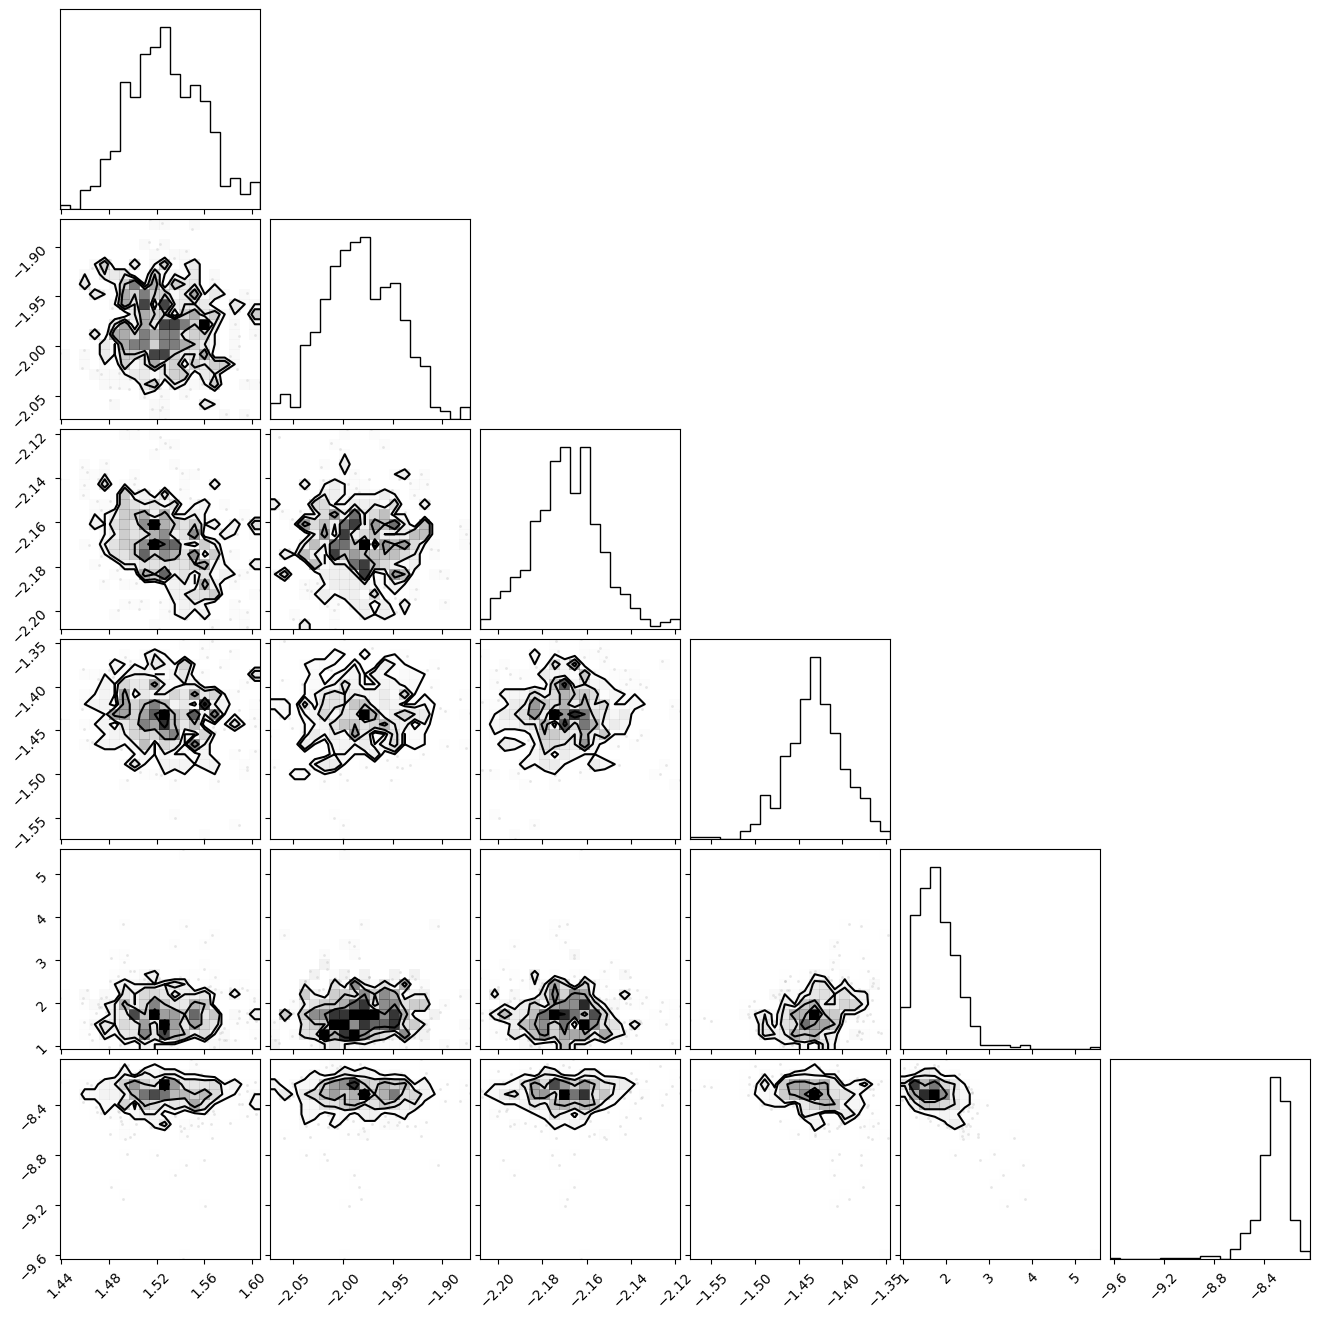

In [ ]:
with np.load(npz_list[-1]) as loaded_results:
    print(loaded_results['raw'])
    figure = corner.corner(
        loaded_results['raw'],
    )
    plt.show()

#### 2026/10/29 18:15:06

In [ ]:
psr = ds.Pulsar.read_feather(f'{PA_path}/J0835-4510.PA.head_derot.minusSBmean.feather', json_metadata=False)
m_RM = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement(psr, tnequad=True),
                         ds.makegp_ecorr(psr),
                         ds.makegp_erm(psr),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp')
                         ])
logL = m_RM.logL

J0835-4510_P574_UWL_efac       mean=+9.652  std=0.350  range=[7.639, 10.000]
J0835-4510_P574_UWL_log10_ecorr mean=-1.919  std=0.034  range=[-2.017, -1.815]
J0835-4510_P574_UWL_log10_tnequad mean=-3.051  std=0.022  range=[-3.103, -2.938]
J0835-4510_log10_erm           mean=-1.432  std=0.032  range=[-1.509, -1.297]
J0835-4510_rmgp_gamma          mean=+1.534  std=0.263  range=[0.804, 1.988]
J0835-4510_rmgp_log10_A        mean=-8.291  std=0.085  range=[-8.612, -8.018]
{'J0835-4510_P574_UWL_efac': np.float64(9.652271541287284), 'J0835-4510_P574_UWL_log10_ecorr': np.float64(-1.9192543957341908), 'J0835-4510_P574_UWL_log10_tnequad': np.float64(-3.050942138752644), 'J0835-4510_log10_erm': np.float64(-1.4324419308554628), 'J0835-4510_rmgp_gamma': np.float64(1.5340360275610267), 'J0835-4510_rmgp_log10_A': np.float64(-8.291083936375541)}
-6.283294e+03


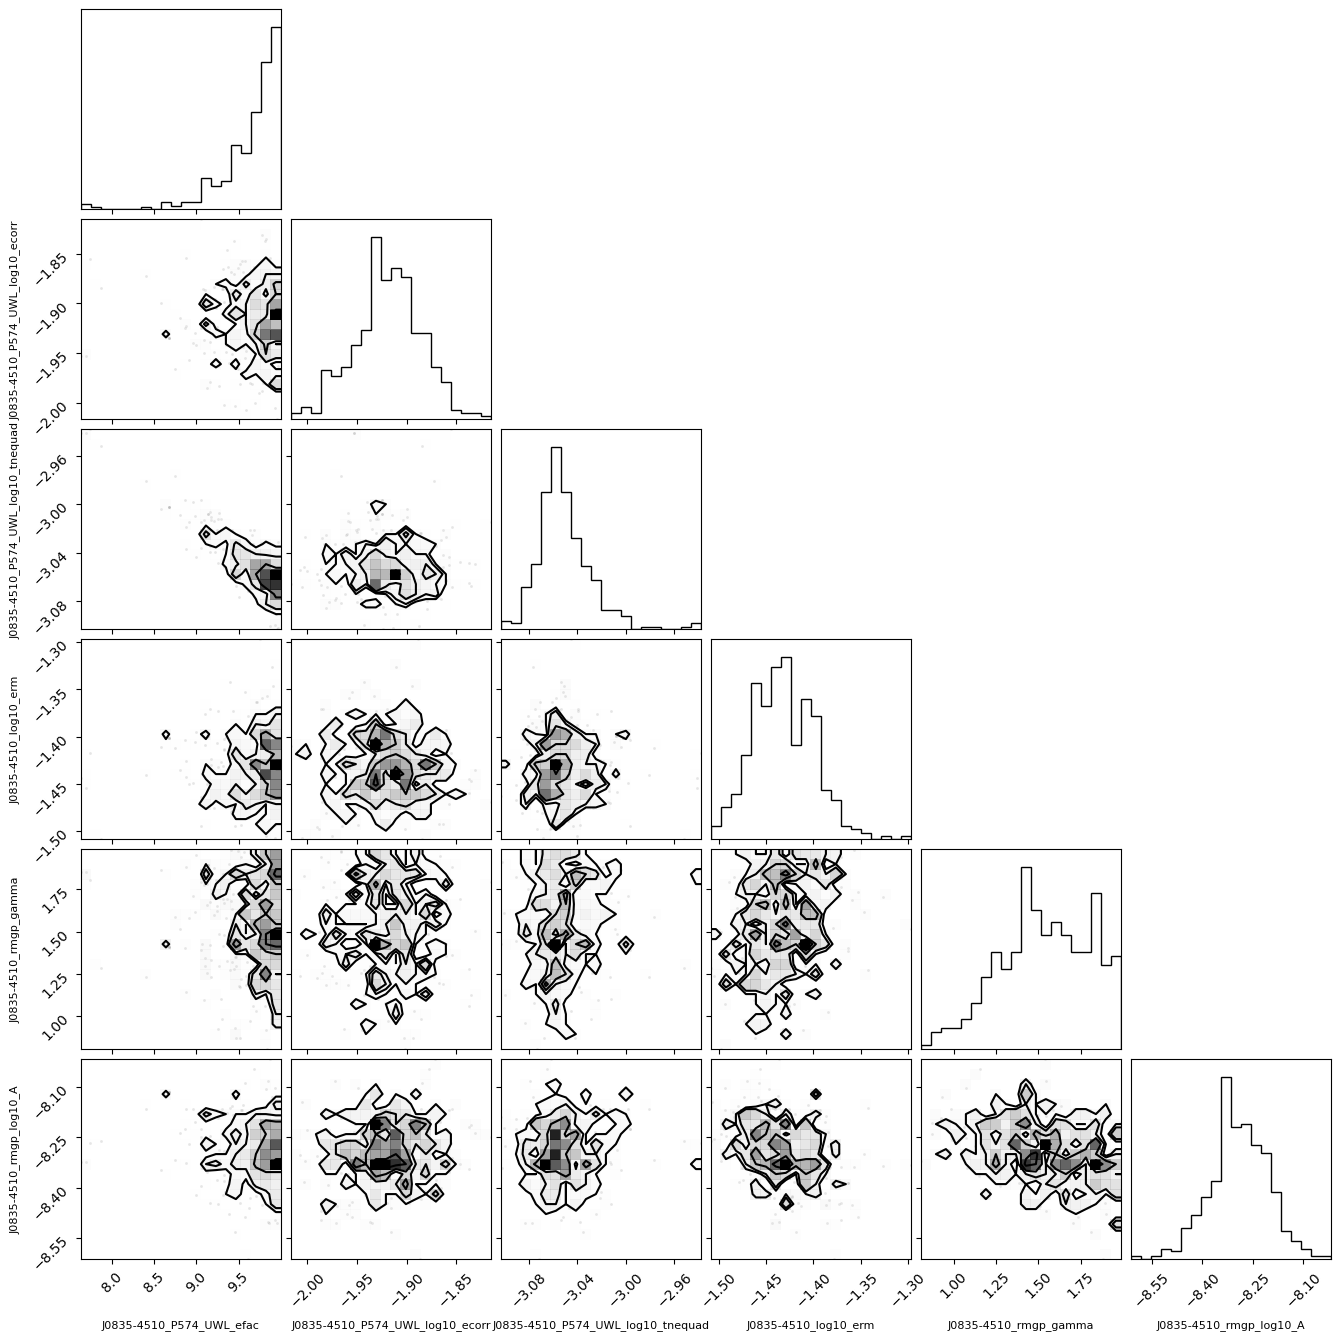

In [ ]:
with np.load(f"{fitres_path}/J0835-4510_mcmc_samples_20261029-181506.npz") as loaded_results:
    raw_samples = loaded_results['raw']

    p_fit = {}
    for i, name in enumerate(logL.params):
        col = raw_samples[:, i]
        print(f'{name:30s} mean={col.mean():+.3f}  std={col.std():.3f}  range=[{min(col):.3f}, {max(col):.3f}]')
        p_fit[name] = col.mean()

    print(p_fit)
    print(f'{logL(p_fit):e}')

    figure = corner.corner(
            loaded_results['raw'],
            labels=logL.params,
            label_kwargs={"fontsize": 8}
        )
    plt.show()

[]

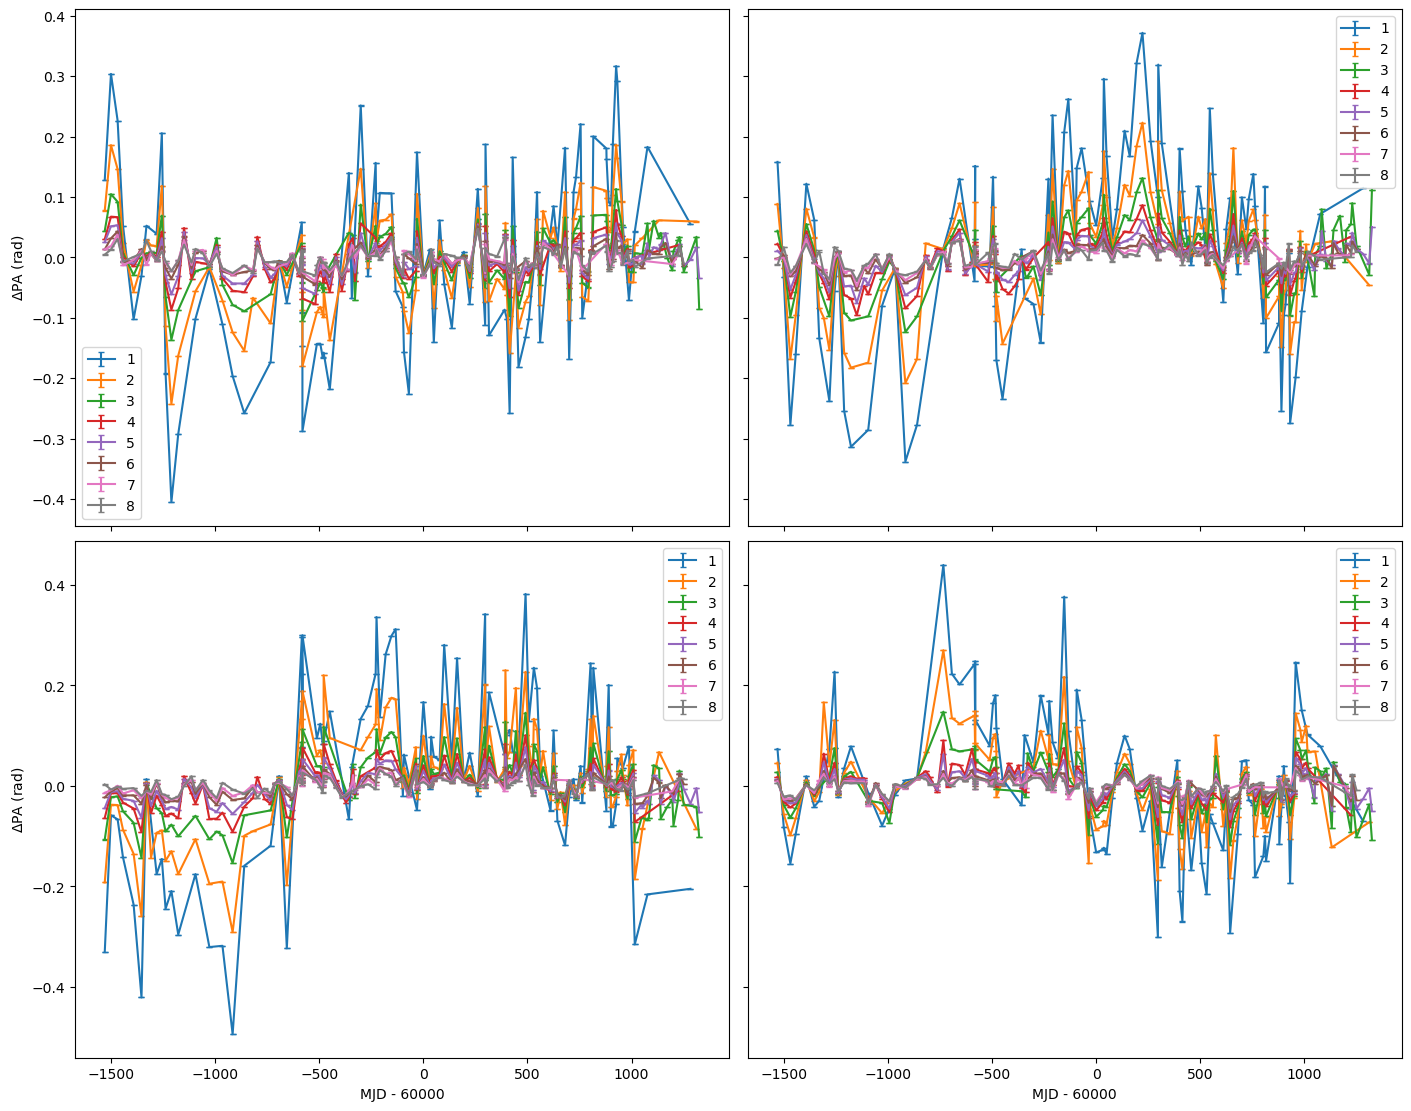

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42+i+2*j)
        key, res = m_RM.sample(key, p_fit)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.legend()

plt.plot()

#### 2026/10/30 20:01:20

In [ ]:
psr = ds.Pulsar.read_feather(f'{PA_path}/J0835-4510.PA.head_derot.minusSBmean.feather', json_metadata=False)
m_RM = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement(psr),
                         ds.makegp_ecorr(psr),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp')
                         ])
logL = m_RM.logL

J0835-4510_P574_UWL_efac       mean=+5.135  std=2.408  range=[0.847, 9.915]
J0835-4510_P574_UWL_log10_ecorr mean=-1.621  std=0.036  range=[-1.724, -1.520]
J0835-4510_P574_UWL_log10_t2equad mean=-2.218  std=0.247  range=[-2.578, -1.511]
J0835-4510_rmgp_gamma          mean=+1.234  std=0.225  range=[0.330, 1.768]
J0835-4510_rmgp_log10_A        mean=-8.136  std=0.049  range=[-8.291, -7.979]
{'J0835-4510_P574_UWL_efac': np.float64(5.135420613133877), 'J0835-4510_P574_UWL_log10_ecorr': np.float64(-1.6208427609343976), 'J0835-4510_P574_UWL_log10_t2equad': np.float64(-2.217738518827997), 'J0835-4510_rmgp_gamma': np.float64(1.234039748152427), 'J0835-4510_rmgp_log10_A': np.float64(-8.136270278949059)}


2.603039e+03


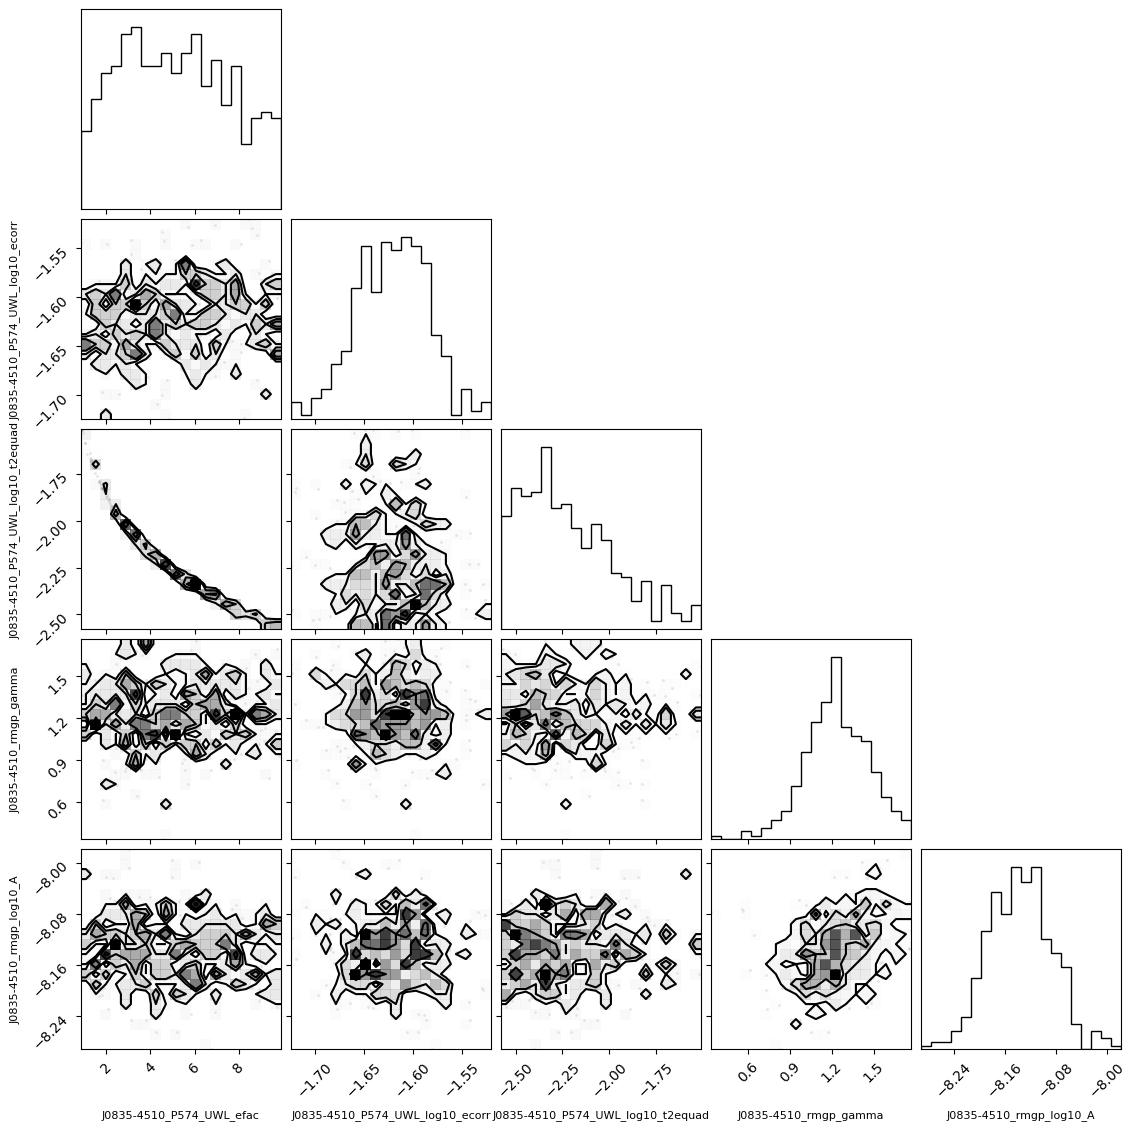

In [ ]:
with np.load(f"{fitres_path}/J0835-4510_mcmc_samples_20261030-200120.npz") as loaded_results:
    raw_samples = loaded_results['raw']

    p_fit = {}
    for i, name in enumerate(logL.params):
        col = raw_samples[:, i]
        print(f'{name:30s} mean={col.mean():+.3f}  std={col.std():.3f}  range=[{min(col):.3f}, {max(col):.3f}]')
        p_fit[name] = col.mean()

    print(p_fit)
    print(f'{logL(p_fit):e}')

    figure = corner.corner(
            loaded_results['raw'],
            labels=logL.params,
            label_kwargs={"fontsize": 8}
        )
    plt.show()

[]

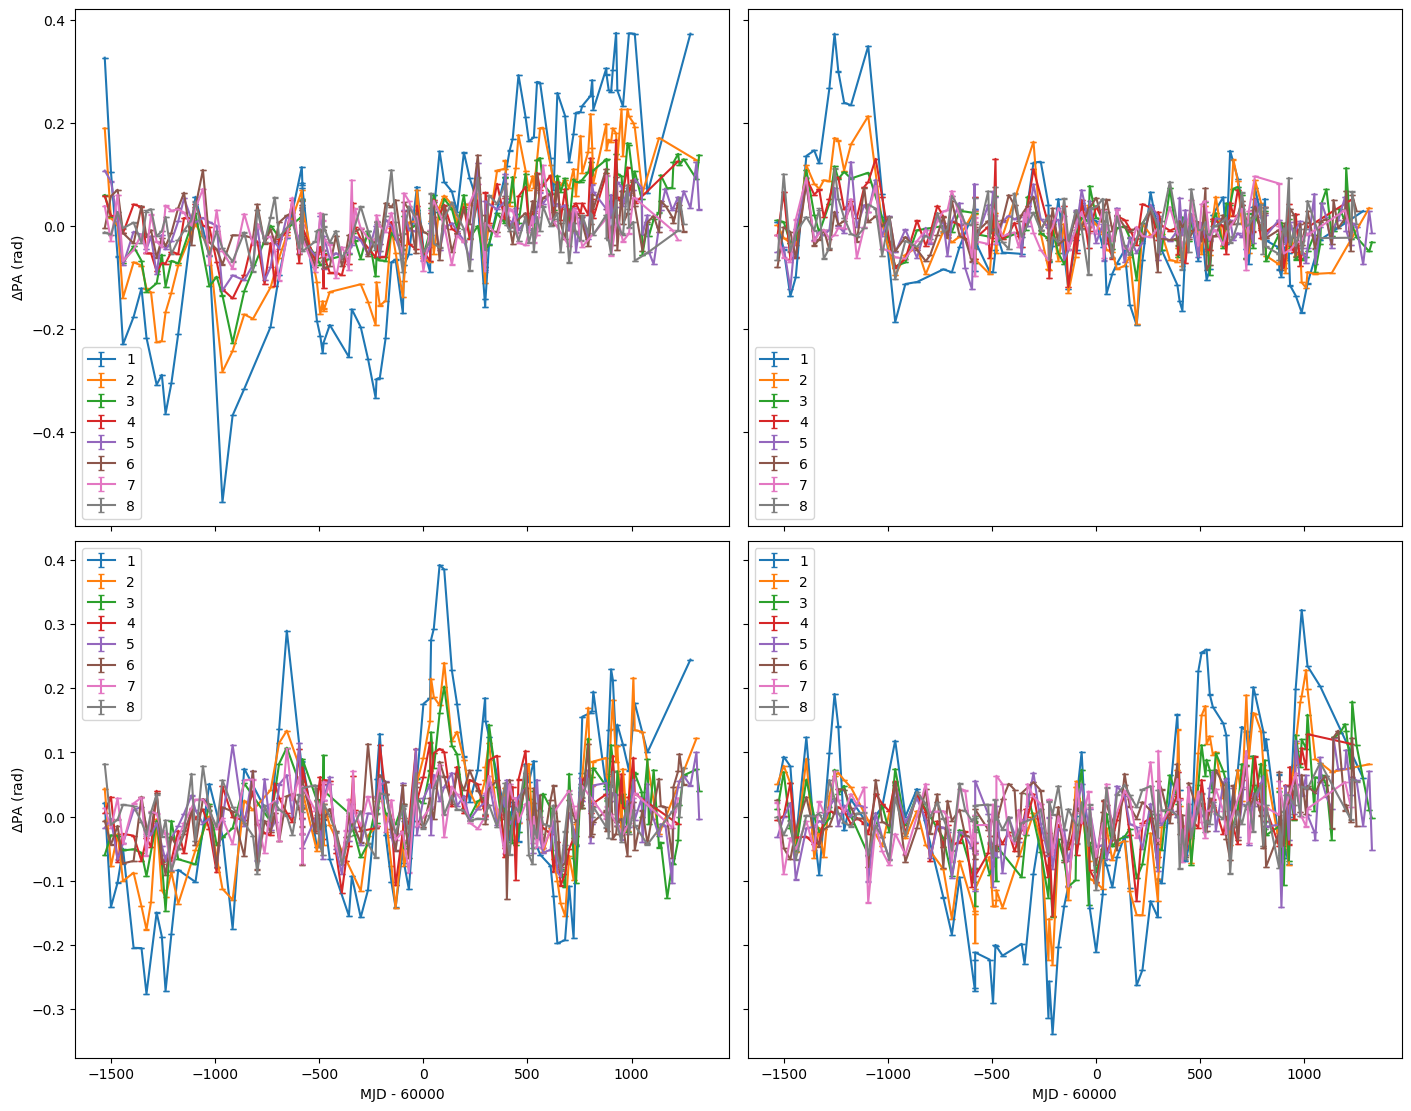

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42+i+2*j)
        key, res = m_RM.sample(key, p_fit)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.legend()

plt.plot()

#### 2026/10/31 17:12:41

In [ ]:
psr = ds.Pulsar.read_feather(f'{PA_path}/J0835-4510.PA.head_derot.minusSBmean.feather', json_metadata=False)
m_RM = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement(psr, tnequad=True),
                         ds.makegp_ecorr(psr),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp')
                         ])
logL = m_RM.logL

J0835-4510_P574_UWL_efac       mean=+4.715  std=2.738  range=[0.111, 9.971]
J0835-4510_P574_UWL_log10_ecorr mean=-1.619  std=0.035  range=[-1.726, -1.516]
J0835-4510_P574_UWL_log10_tnequad mean=-1.566  std=0.012  range=[-1.605, -1.528]
J0835-4510_rmgp_gamma          mean=+1.274  std=0.237  range=[0.460, 1.868]
J0835-4510_rmgp_log10_A        mean=-8.130  std=0.048  range=[-8.237, -7.998]
{'J0835-4510_P574_UWL_efac': np.float64(4.714722365603481), 'J0835-4510_P574_UWL_log10_ecorr': np.float64(-1.6194373961863937), 'J0835-4510_P574_UWL_log10_tnequad': np.float64(-1.5663591087027993), 'J0835-4510_rmgp_gamma': np.float64(1.2740636085909158), 'J0835-4510_rmgp_log10_A': np.float64(-8.12953460125679)}
2.615701e+03


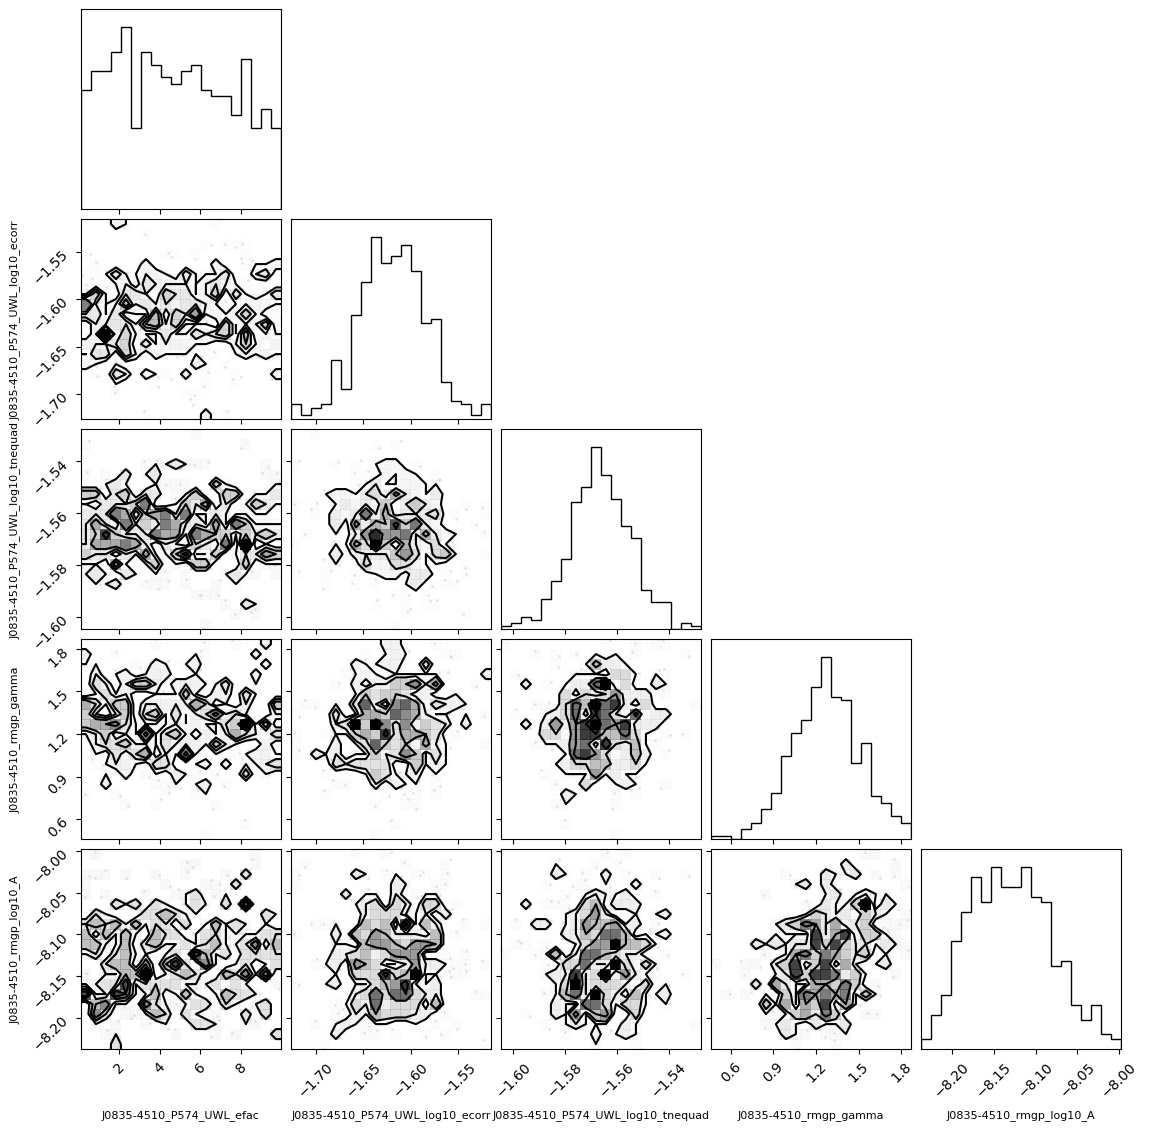

In [ ]:
with np.load(f"{fitres_path}/J0835-4510_mcmc_samples_20261031-171241.npz") as loaded_results:
    raw_samples = loaded_results['raw']

    p_fit = {}
    for i, name in enumerate(logL.params):
        col = raw_samples[:, i]
        print(f'{name:30s} mean={col.mean():+.3f}  std={col.std():.3f}  range=[{min(col):.3f}, {max(col):.3f}]')
        p_fit[name] = col.mean()

    print(p_fit)
    print(f'{logL(p_fit):e}')

    figure = corner.corner(
            loaded_results['raw'],
            labels=logL.params,
            label_kwargs={"fontsize": 8}
        )
    plt.show()

[]

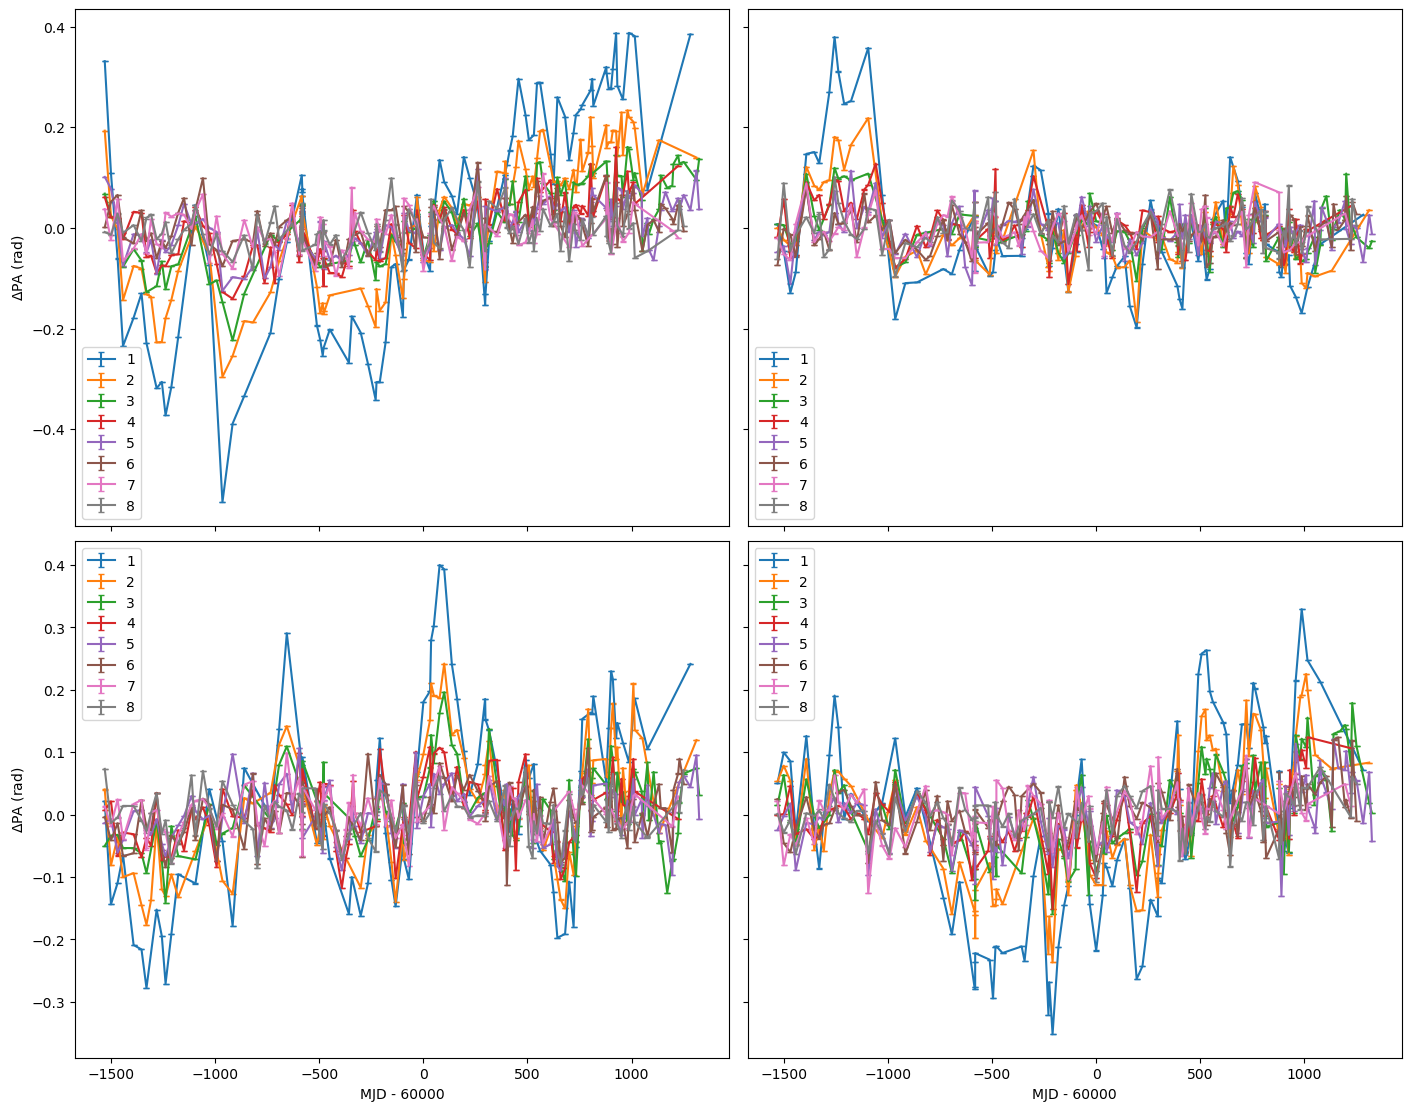

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42+i+2*j)
        key, res = m_RM.sample(key, p_fit)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.legend()

plt.plot()

#### 2026/10/31 23:43:18

J0835-4510_P574_UWL_efac_log10 mean=-0.056  std=0.546  range=[-0.986, 0.993]
J0835-4510_P574_UWL_log10_ecorr mean=-1.617  std=0.035  range=[-1.736, -1.518]
J0835-4510_P574_UWL_log10_tnequad mean=-1.567  std=0.011  range=[-1.597, -1.532]
J0835-4510_rmgp_gamma          mean=+1.266  std=0.246  range=[0.460, 1.884]
J0835-4510_rmgp_log10_A        mean=-8.132  std=0.045  range=[-8.244, -7.993]
{'J0835-4510_P574_UWL_efac_log10': np.float64(-0.05614844737755823), 'J0835-4510_P574_UWL_log10_ecorr': np.float64(-1.6168429420037547), 'J0835-4510_P574_UWL_log10_tnequad': np.float64(-1.5669319189178532), 'J0835-4510_rmgp_gamma': np.float64(1.2664781821352171), 'J0835-4510_rmgp_log10_A': np.float64(-8.132460399172608)}
2.615798e+03


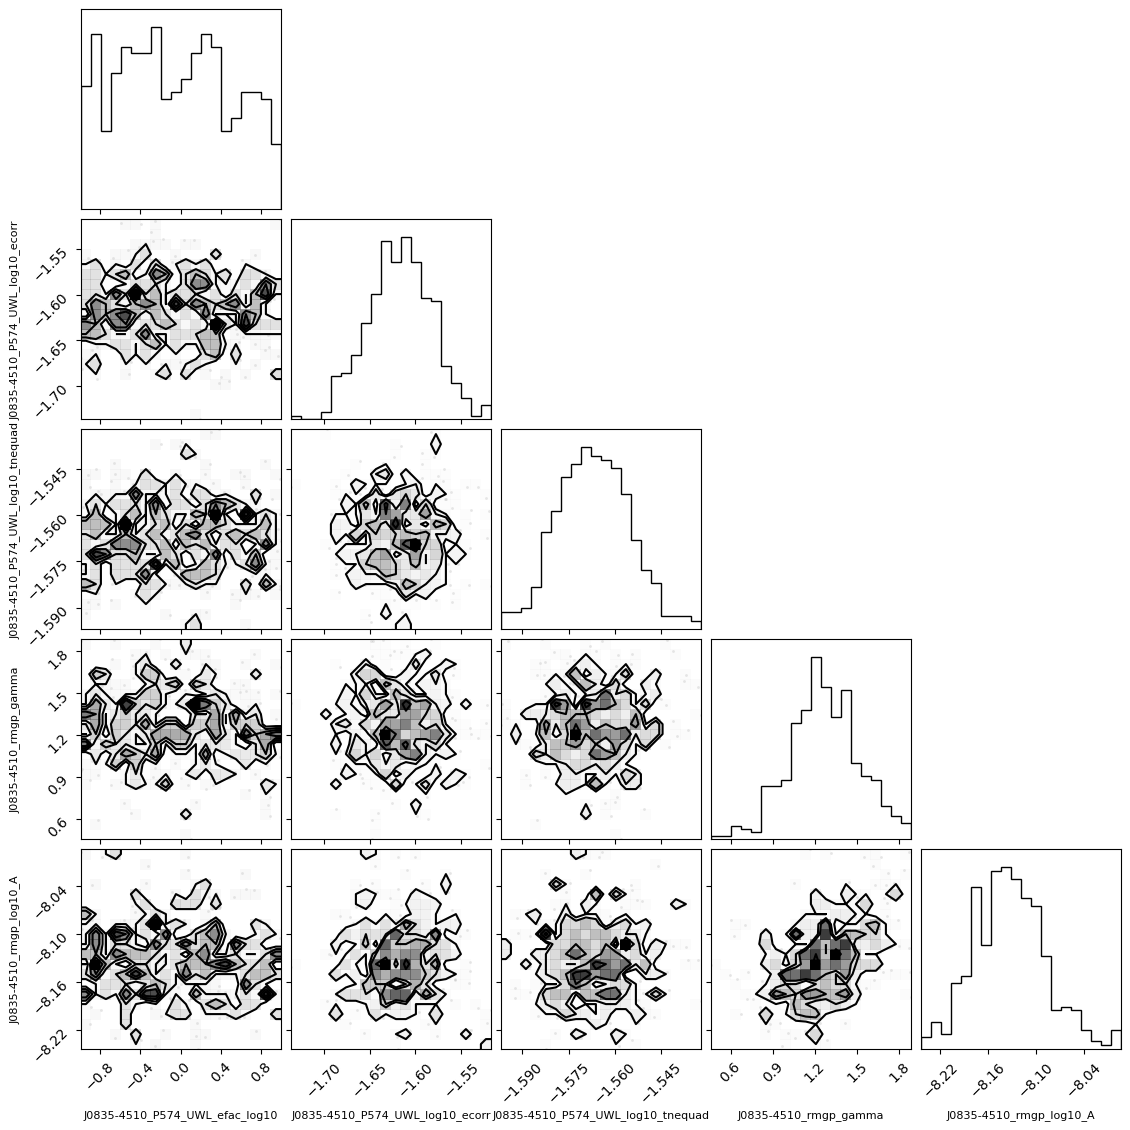

In [ ]:
psr = ds.Pulsar.read_feather(f'{PA_path}/J0835-4510.PA.head_derot.minusSBmean.feather', json_metadata=False)
m_RM = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement(psr, tnequad=True, log_efac=True),
                         ds.makegp_ecorr(psr),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp')
                         ])
logL = m_RM.logL

with np.load(f"{fitres_path}/J0835-4510_mcmc_samples_20261031-234318.npz") as loaded_results:
    raw_samples = loaded_results['raw']

    p_fit = {}
    for i, name in enumerate(logL.params):
        col = raw_samples[:, i]
        print(f'{name:30s} mean={col.mean():+.3f}  std={col.std():.3f}  range=[{min(col):.3f}, {max(col):.3f}]')
        p_fit[name] = col.mean()

    print(p_fit)
    print(f'{logL(p_fit):e}')

    figure = corner.corner(
            loaded_results['raw'],
            labels=logL.params,
            label_kwargs={"fontsize": 8}
        )
    plt.show()

[]

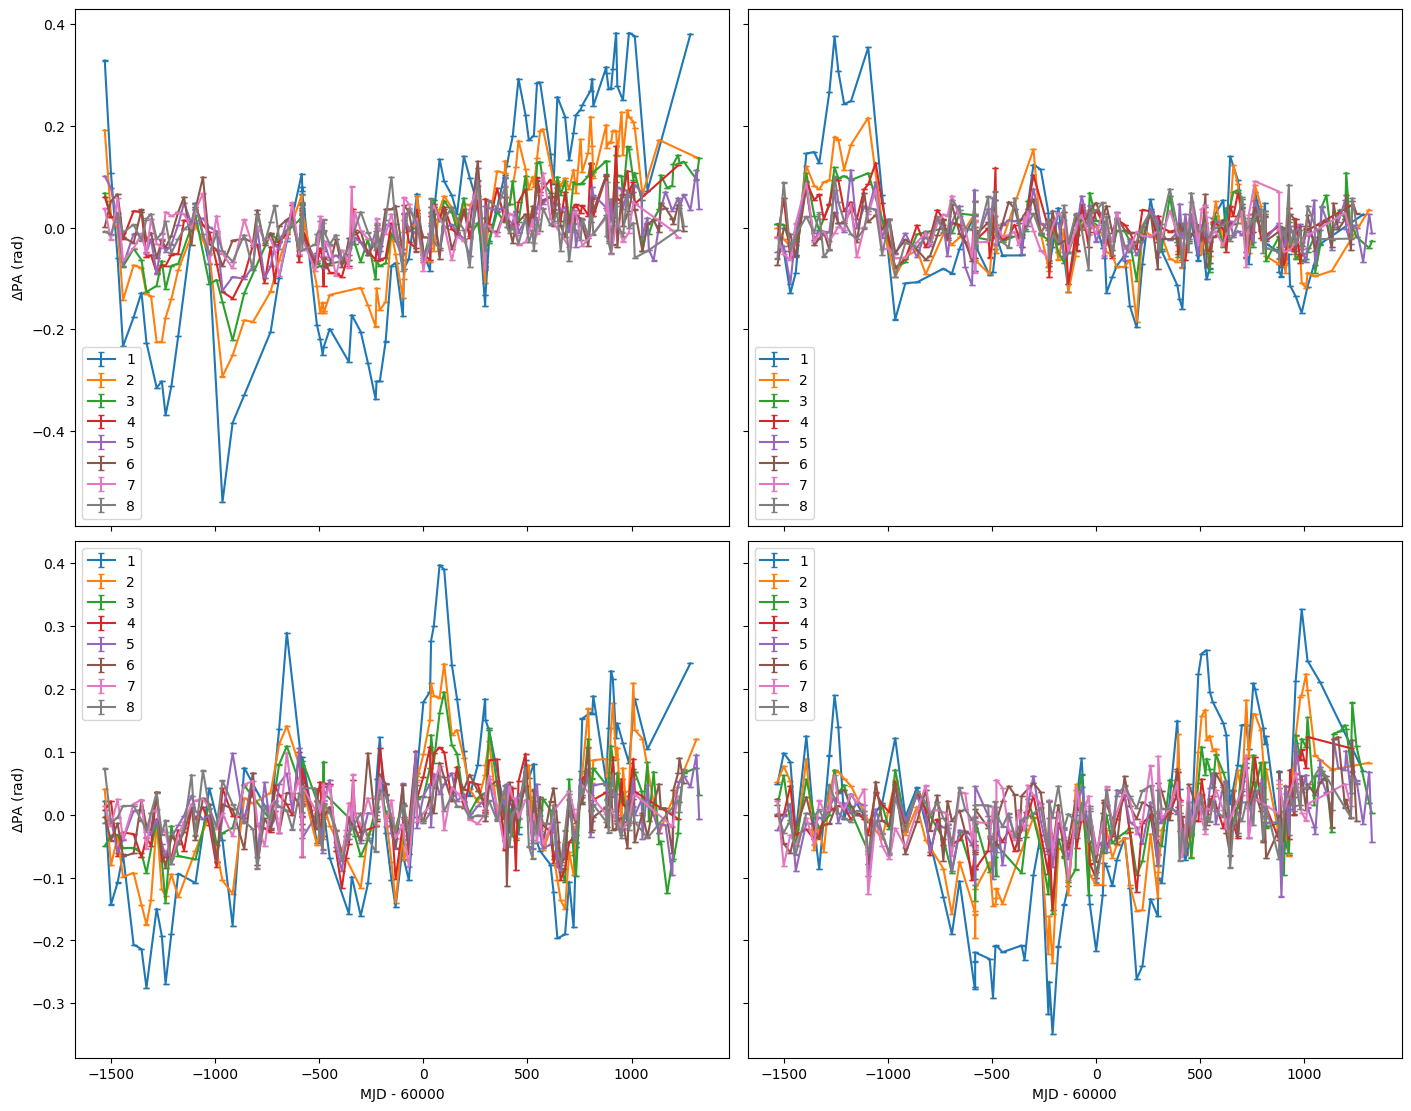

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42+i+2*j)
        key, res = m_RM.sample(key, p_fit)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.legend()

plt.plot()

#### 2026/10/31 23:59:35

J0835-4510_P574_UWL_efac_log10 mean=+0.983  std=0.019  range=[0.884, 1.000]
J0835-4510_P574_UWL_log10_ecorr mean=-1.918  std=0.036  range=[-2.013, -1.801]
J0835-4510_P574_UWL_log10_tnequad mean=-2.068  std=0.014  range=[-2.118, -2.034]
J0835-4510_log10_erm           mean=-1.437  std=0.032  range=[-1.537, -1.349]
J0835-4510_rmgp_gamma          mean=+1.559  std=0.254  range=[0.938, 1.998]
J0835-4510_rmgp_log10_A        mean=-8.288  std=0.093  range=[-8.567, -8.058]
{'J0835-4510_P574_UWL_efac_log10': np.float64(0.982596195648743), 'J0835-4510_P574_UWL_log10_ecorr': np.float64(-1.9180397388200772), 'J0835-4510_P574_UWL_log10_tnequad': np.float64(-2.0679435126260057), 'J0835-4510_log10_erm': np.float64(-1.436593880888439), 'J0835-4510_rmgp_gamma': np.float64(1.5590740690472602), 'J0835-4510_rmgp_log10_A': np.float64(-8.287573236768155)}
3.362635e+03


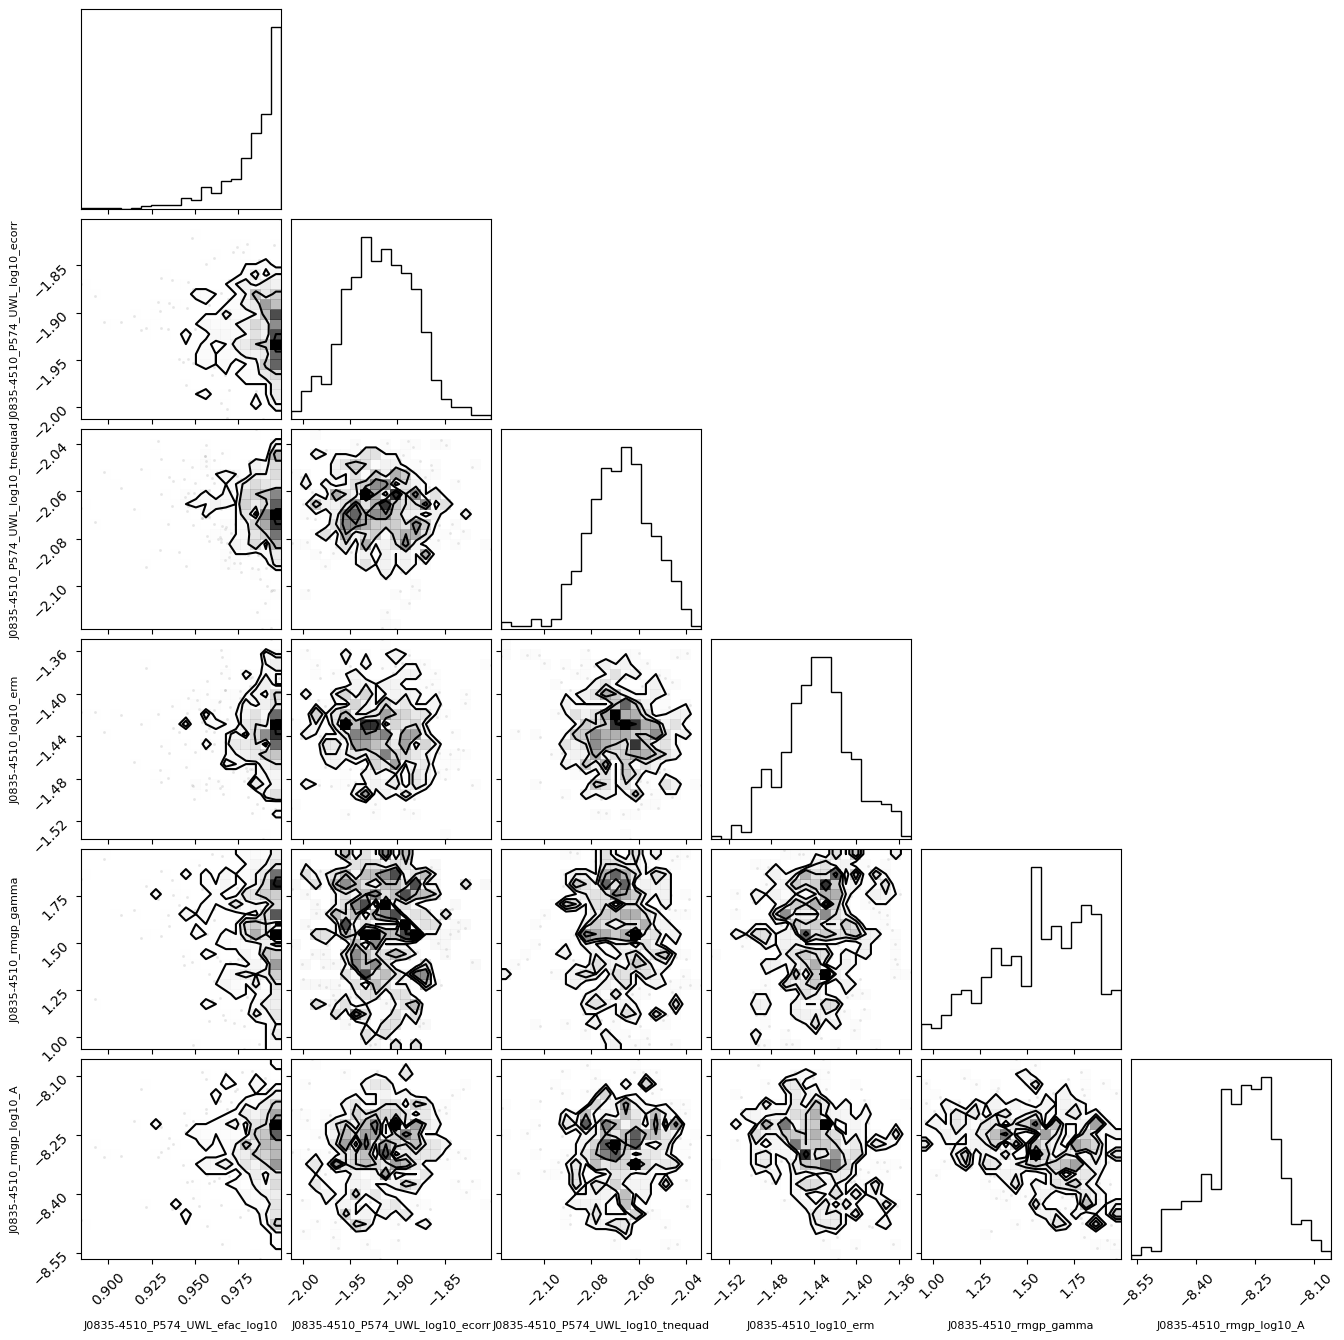

In [ ]:
psr = ds.Pulsar.read_feather(f'{PA_path}/J0835-4510.PA.head_derot.minusSBmean.feather', json_metadata=False)
m_RM = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement(psr, tnequad=True, log_efac=True),
                         ds.makegp_ecorr(psr),
                         ds.makegp_erm(psr),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp')
                         ])
logL = m_RM.logL

with np.load(f"{fitres_path}/J0835-4510_mcmc_samples_20261031-235935.npz") as loaded_results:
    raw_samples = loaded_results['raw']

    p_fit = {}
    for i, name in enumerate(logL.params):
        col = raw_samples[:, i]
        print(f'{name:30s} mean={col.mean():+.3f}  std={col.std():.3f}  range=[{min(col):.3f}, {max(col):.3f}]')
        p_fit[name] = col.mean()

    print(p_fit)
    print(f'{logL(p_fit):e}')

    figure = corner.corner(
            loaded_results['raw'],
            labels=logL.params,
            label_kwargs={"fontsize": 8}
        )
    plt.show()

[]

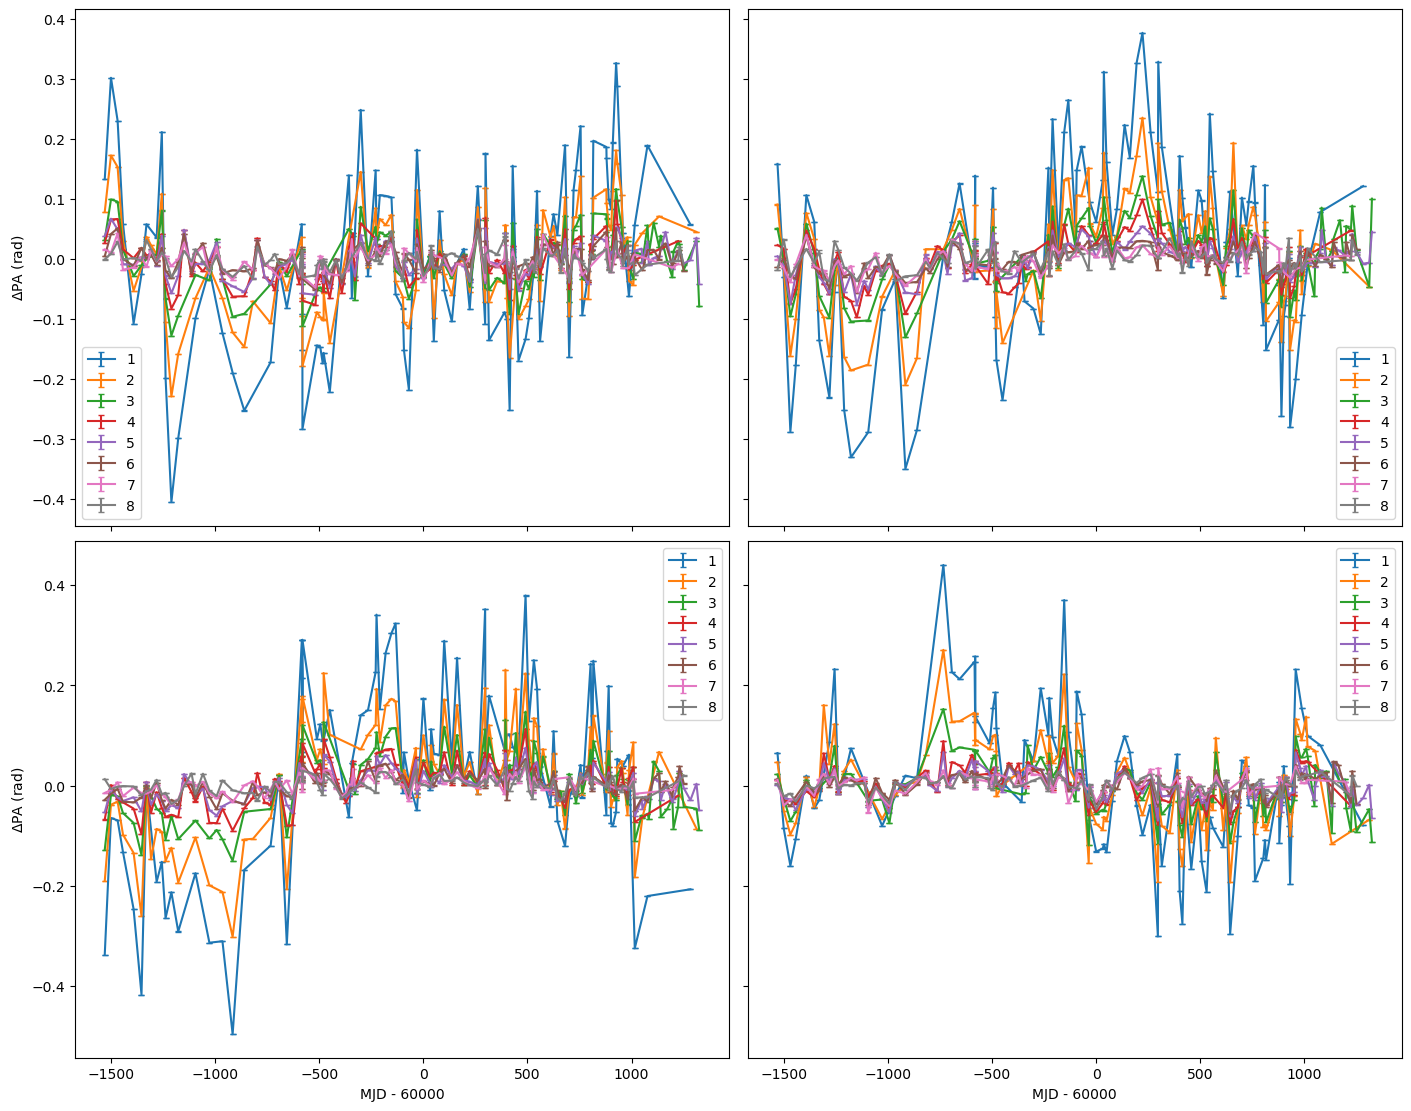

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42+i+2*j)
        key, res = m_RM.sample(key, p_fit)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.legend()

plt.plot()

#### 2026/11/01 18:30:16

J0835-4510_P574_UWL_efac_log10 mean=+1.527  std=0.030  range=[1.439, 1.606]
J0835-4510_P574_UWL_log10_ecorr mean=-1.982  std=0.036  range=[-2.073, -1.873]
J0835-4510_P574_UWL_log10_tnequad mean=-2.169  std=0.016  range=[-2.208, -2.118]
J0835-4510_log10_erm           mean=-1.432  std=0.033  range=[-1.575, -1.346]
J0835-4510_rmgp_gamma          mean=+1.787  std=0.494  range=[0.919, 5.575]
J0835-4510_rmgp_log10_A        mean=-8.334  std=0.155  range=[-9.632, -8.032]
{'J0835-4510_P574_UWL_efac_log10': np.float64(1.5267776222944511), 'J0835-4510_P574_UWL_log10_ecorr': np.float64(-1.982062980526513), 'J0835-4510_P574_UWL_log10_tnequad': np.float64(-2.1690902632427465), 'J0835-4510_log10_erm': np.float64(-1.4319712441650523), 'J0835-4510_rmgp_gamma': np.float64(1.7871627431158754), 'J0835-4510_rmgp_log10_A': np.float64(-8.334288519892233)}
3.413815e+03


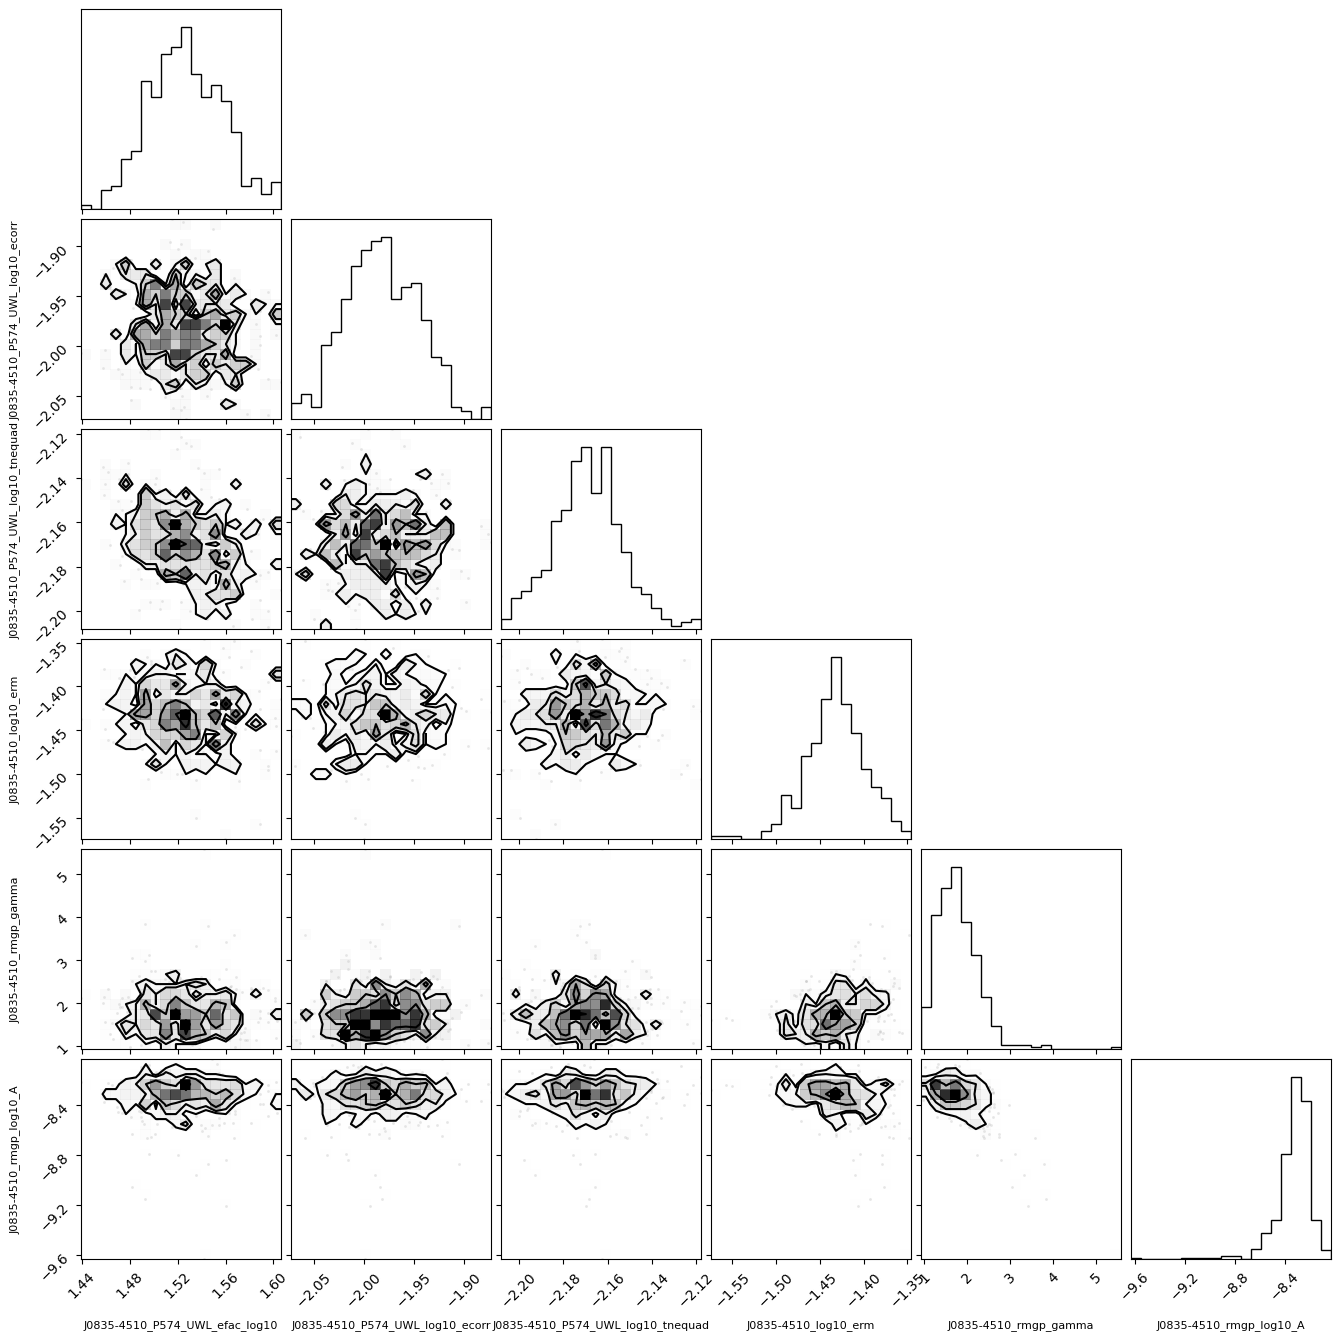

In [ ]:
psr = ds.Pulsar.read_feather(f'{PA_path}/J0835-4510.PA.head_derot.minusSBmean.feather', json_metadata=False)
m_RM = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement(psr, tnequad=True, log_efac=True),
                         ds.makegp_ecorr(psr),
                         ds.makegp_erm(psr),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp')
                         ])
logL = m_RM.logL

with np.load(f"{fitres_path}/J0835-4510_mcmc_samples_20261101-183016.npz") as loaded_results:
    raw_samples = loaded_results['raw']

    p_fit = {}
    for i, name in enumerate(logL.params):
        col = raw_samples[:, i]
        print(f'{name:30s} mean={col.mean():+.3f}  std={col.std():.3f}  range=[{min(col):.3f}, {max(col):.3f}]')
        p_fit[name] = col.mean()

    print(p_fit)
    print(f'{logL(p_fit):e}')

    figure = corner.corner(
            loaded_results['raw'],
            labels=logL.params,
            label_kwargs={"fontsize": 8}
        )
    plt.show()

[]

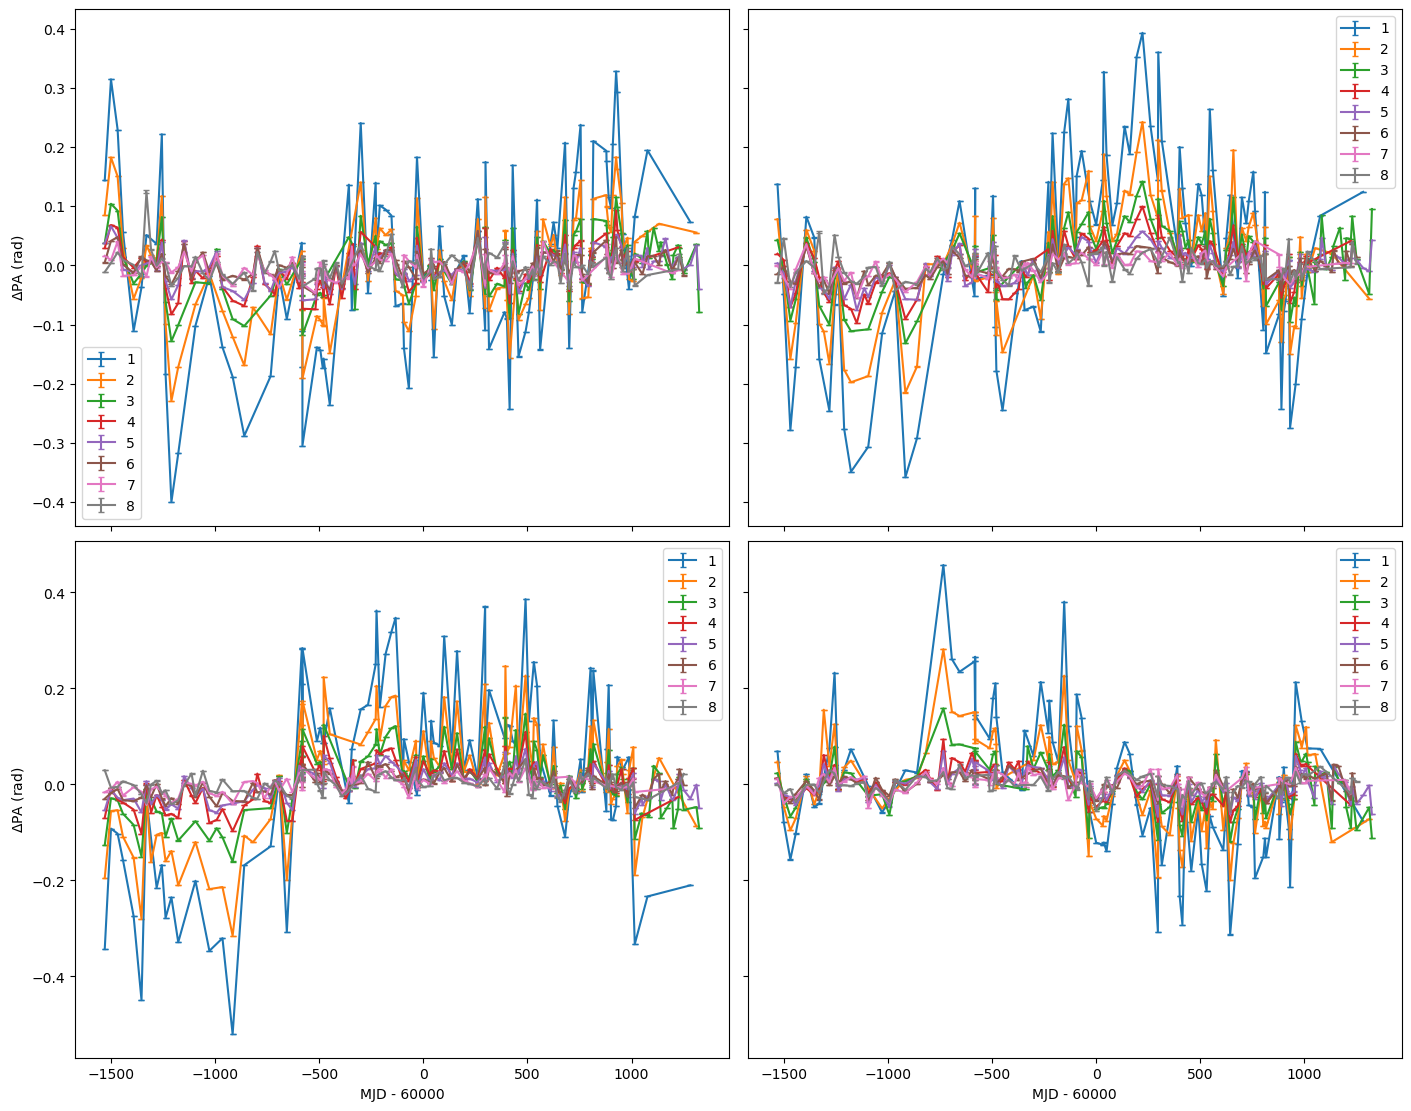

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42+i+2*j)
        key, res = m_RM.sample(key, p_fit)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.legend()

plt.plot()

#### 2026/11/03 21:40:28 (first run with ALDM signal)

J0835-4510_P574_UWL_efac_log10 mean=+1.525  std=0.032  range=[1.434, 1.619]
J0835-4510_P574_UWL_log10_ecorr mean=-1.984  std=0.040  range=[-2.103, -1.880]
J0835-4510_P574_UWL_log10_tnequad mean=-2.170  std=0.017  range=[-2.224, -2.117]
J0835-4510_log10_erm           mean=-1.427  std=0.035  range=[-1.514, -1.316]
J0835-4510_rmgp_gamma          mean=+1.776  std=0.527  range=[0.738, 3.968]
J0835-4510_rmgp_log10_A        mean=-8.350  std=0.159  range=[-9.068, -8.098]
log10_Sa                       mean=-5.211  std=1.497  range=[-7.981, -2.193]
{'J0835-4510_P574_UWL_efac_log10': np.float64(1.5246821293017876), 'J0835-4510_P574_UWL_log10_ecorr': np.float64(-1.9844797202726718), 'J0835-4510_P574_UWL_log10_tnequad': np.float64(-2.169693098125496), 'J0835-4510_log10_erm': np.float64(-1.4273058137596113), 'J0835-4510_rmgp_gamma': np.float64(1.77552929234366), 'J0835-4510_rmgp_log10_A': np.float64(-8.349671551480046), 'log10_Sa': np.float64(-5.210562841637983)}
3.413747e+03
95th percentile of log

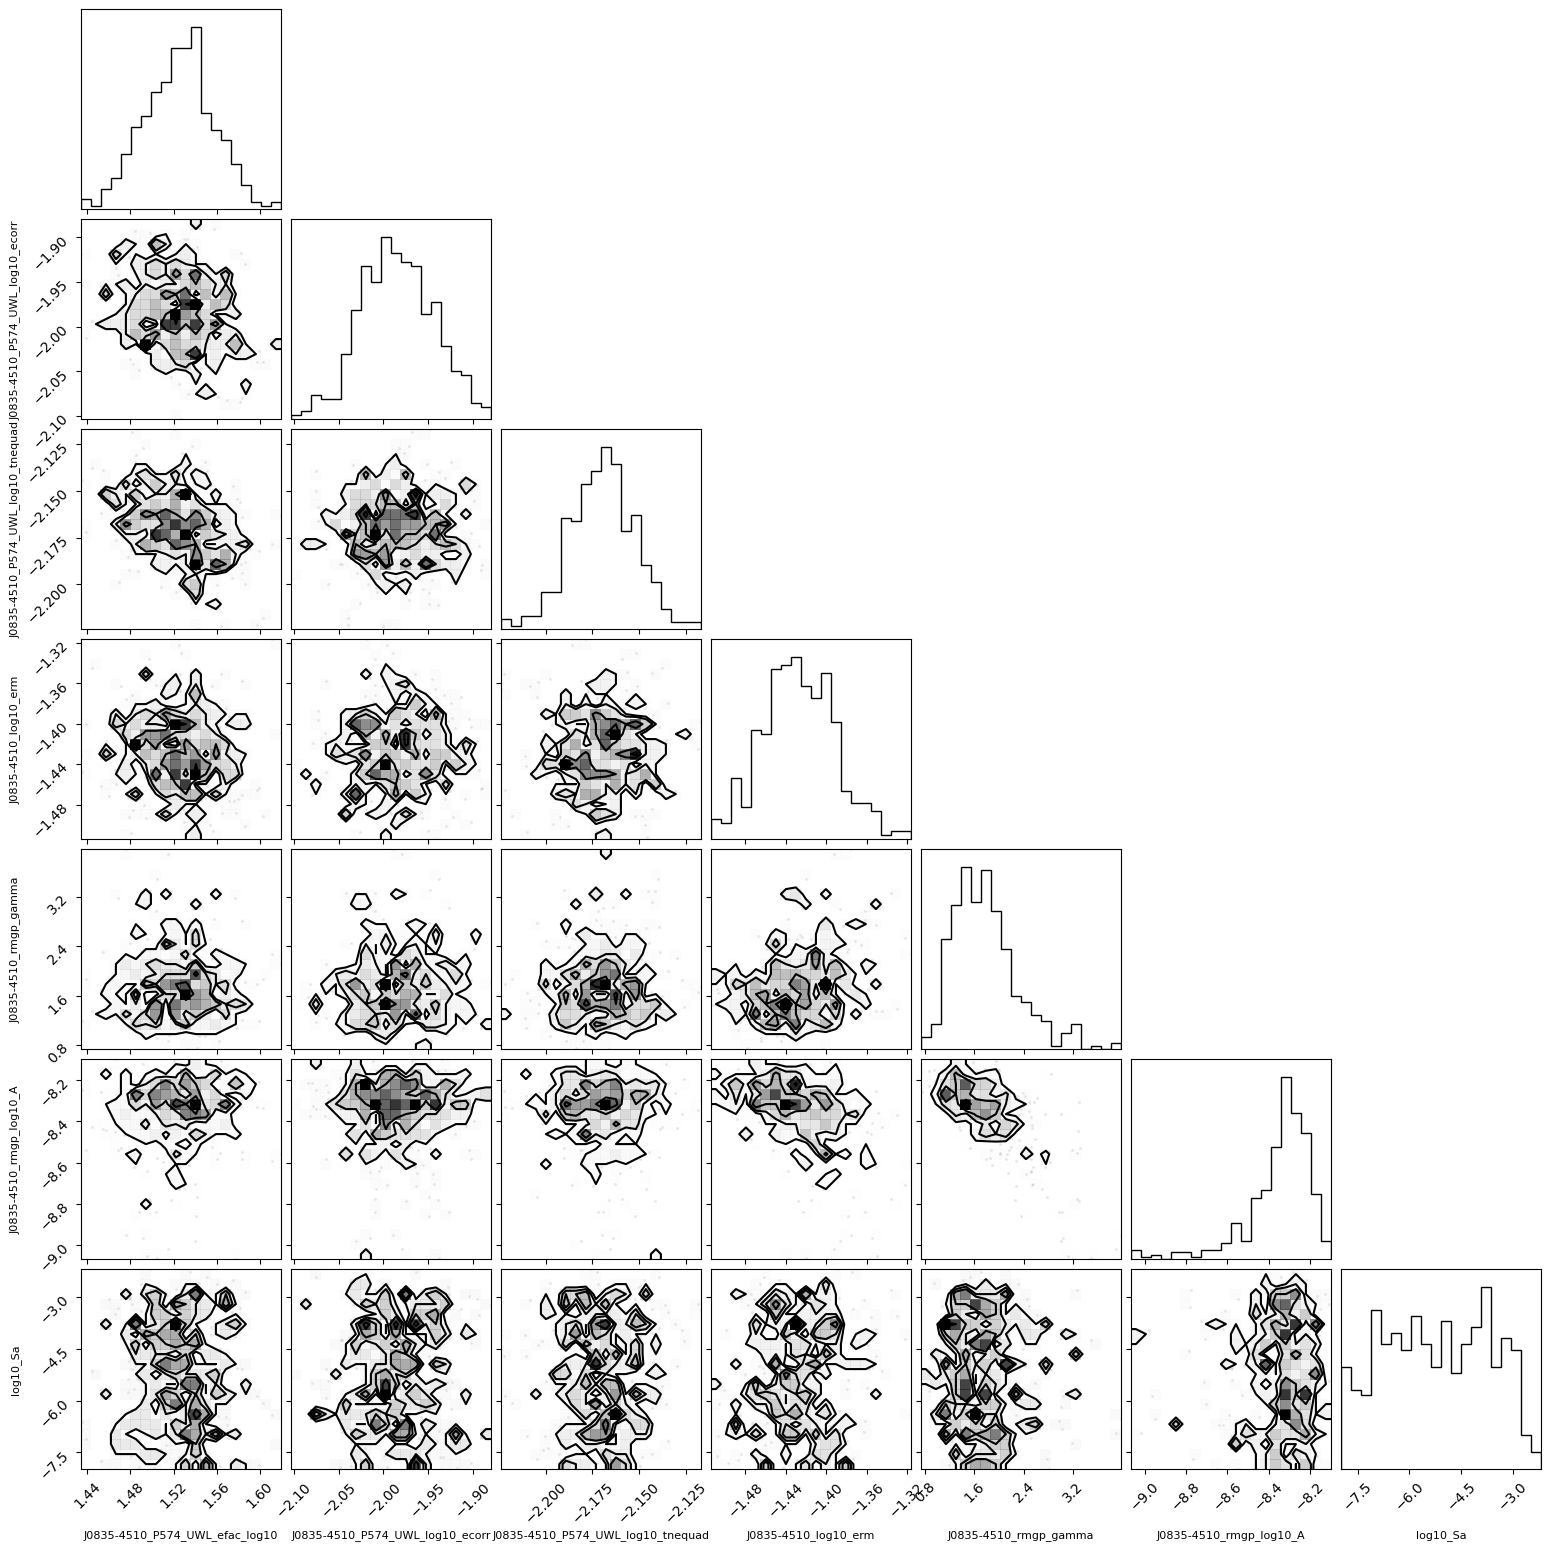

In [6]:
psr = ds.Pulsar.read_feather(f'{PA_path}/J0835-4510.PA.head_derot.minusSBmean.feather', json_metadata=False)
psr.dist0 = 0.280 # kpc
m_aldm = ds.PulsarLikelihood([psr.residuals,
                         ds.makenoise_measurement(psr, tnequad=True, log_efac=True),
                         ds.makegp_ecorr(psr),
                         ds.makegp_erm(psr),
                         ds.makegp_fourier(psr, ds.powerlaw, components=30, fourierbasis=ds.fourierbasis_dm, name='rmgp'),
                         ds.makegp_aldm_psr(psr,-23.0)
                         ])
logL = m_aldm.logL

with np.load(f"{fitres_path}/J0835-4510_mcmc_samples_20261103-214028.npz") as loaded_results:
    raw_samples = loaded_results['raw']

    p_fit = {}
    for i, name in enumerate(logL.params):
        col = raw_samples[:, i]
        print(f'{name:30s} mean={col.mean():+.3f}  std={col.std():.3f}  range=[{min(col):.3f}, {max(col):.3f}]')
        p_fit[name] = col.mean()

    print(p_fit)
    print(f'{logL(p_fit):e}')

    log10_Sa_samples = raw_samples[:, i]
    log10_Sa_95 = np.percentile(log10_Sa_samples, 95)
    print(f'95th percentile of log10(S_a/rad): {log10_Sa_95}')
    Sa_95 = 10**np.percentile(log10_Sa_samples, 95)
    print(f'95th percentile of S_a (rad):      {Sa_95}')

    Sa_95_deg = np.rad2deg(Sa_95)
    log10_Sa_95_deg = np.log10(Sa_95_deg)
    print(f'95th percentile of log10(S_a/deg): {log10_Sa_95_deg}')
    print(f'95th percentile of S_a (deg):      {Sa_95_deg}')

    coupling_95 = ds.Sa_to_coupling(Sa_95, 1e-23, DM_density=0.4)
    print(f'Corresponding coupling (GeV^-1):   {coupling_95}')

    figure = corner.corner(
            loaded_results['raw'],
            labels=logL.params,
            label_kwargs={"fontsize": 8}
        )
    plt.show()

[]

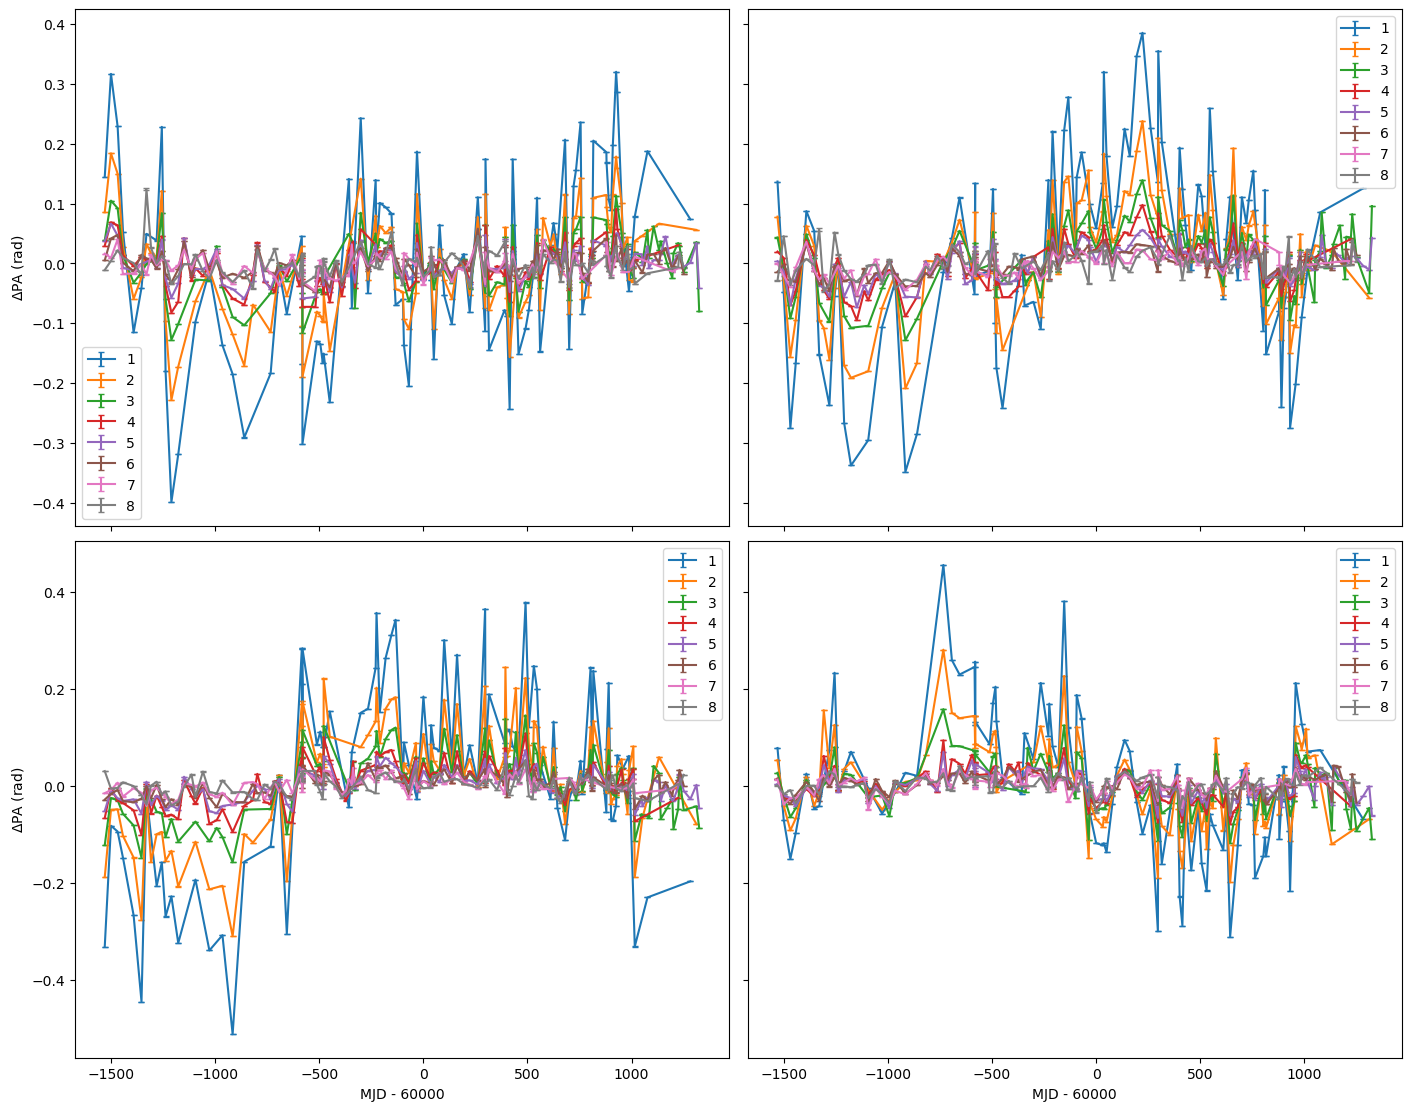

In [8]:
fig, axs = plt.subplots(2, 2, figsize=(14, 11), sharex='col', sharey='row', layout='constrained')

for i in range(2):
    for j in range(2):
        ax = axs[i][j]

        # should jit the sampler if simulating many datasets
        key = ds.rngkey(42+i+2*j)
        
        key, res = m_aldm.sample(key, p_fit)

        for sb in range(1,8+1):
            mask = psr.subbands == sb
            t = Time(psr.toas[mask], format='unix', scale='utc')
            ax.errorbar(t.mjd-60000, 
                        # np.degrees(
                            res[mask],
                            # ), 
                        # np.degrees(
                            psr.toaerrs[mask],
                            # ), 
                        capsize=2.5, label=sb)

        if i==1:
            ax.set_xlabel('MJD - 60000')
        if j==0:
            ax.set_ylabel('$\\Delta$PA (rad)')
        ax.legend()

plt.plot()